# Chapter 12: Layers as polarizers

Checks [chapter 12](../../book/12-polarizers.md). The models are small and exact: ReLU on the plane, a polarizer
as a projection onto an axis (a 2 by 2 matrix), random layers as random functions on a finite set of states, and a
**linear model in its weights** with tight features for the last claim. Everything is NumPy in float64, seeded.
These are measurements, not proofs: the proofs are in `Polarizer.lean`, `ThreePolarizers.lean` and `MarkovChains.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 12


def apply_relu(points):
    return np.maximum(points, 0.0)


def make_plate(plate_angle):
    """A polarizer with its axis at plate_angle: it keeps the part of the light along the axis."""
    axis = np.array([np.cos(plate_angle), np.sin(plate_angle)])
    return np.outer(axis, axis)


def pass_through_plates(plate_angles, light):
    """Send light through the plates in order. Each plate keeps the part along its own axis."""
    for plate_angle in plate_angles:
        light = make_plate(plate_angle) @ light
    return light

## Claim 1: ReLU on both coordinates is the nearest point of the positive quadrant (`relu2_nearest`)

Take 200 random points of the plane in `[-3, 3]^2` and apply ReLU to both coordinates. Compare with a brute-force
search: the distance from the point to every point of a grid on the quadrant `[0, 3]^2` with spacing 0.01 (about 90 000
grid points). The ReLU point must be no further than any grid point, and the best grid point must be within half a grid diagonal of it.
The control: a point pushed 0.05 away from the ReLU point inside the quadrant must never be nearer.

In [2]:
generator = np.random.default_rng(SEED)
GRID_STEP = 0.01
grid_axis = np.arange(0.0, 3.0 + GRID_STEP / 2, GRID_STEP)
grid_x, grid_y = np.meshgrid(grid_axis, grid_axis)
grid_points = np.stack([grid_x.ravel(), grid_y.ravel()], axis=1)

points = generator.uniform(-3, 3, size=(200, 2))
worst_excess = -np.inf       # relu distance minus the best grid distance: must be <= 0
worst_shortfall = 0.0        # best grid distance minus relu distance: at most half a grid diagonal
shifted_closer = 0
for point in points:
    relu_point = apply_relu(point)
    relu_distance = np.linalg.norm(point - relu_point)
    best_grid_distance = np.linalg.norm(grid_points - point, axis=1).min()
    worst_excess = max(worst_excess, relu_distance - best_grid_distance)
    worst_shortfall = max(worst_shortfall, best_grid_distance - relu_distance)
    shifted = relu_point + 0.05 * np.abs(generator.standard_normal(2))
    shifted_closer += np.linalg.norm(point - shifted) < relu_distance - 1e-12
report("ReLU is no further than any of the 90 000 grid points, for 200 points", worst_excess <= 1e-12,
       f"largest relu minus best grid {worst_excess:.1e}")
report("the best grid point is within half a grid diagonal of the ReLU distance",
       worst_shortfall <= GRID_STEP * np.sqrt(2) / 2 + 1e-12, f"largest gap {worst_shortfall:.4f}")
report("control: points pushed 0.05 away inside the quadrant are never nearer", shifted_closer == 0, f"{shifted_closer} nearer")

[PASS] ReLU is no further than any of the 90 000 grid points, for 200 points  (largest relu minus best grid 4.4e-16)
[PASS] the best grid point is within half a grid diagonal of the ReLU distance  (largest gap 0.0060)
[PASS] control: points pushed 0.05 away inside the quadrant are never nearer  (0 nearer)


True

## Claim 2: Malus's law, and a crossed plate passes nothing (`malus`, `polarizer_crossed`)

Light of length `amplitude` at angle zero meets a plate turned by `turn_angle`. What passes, measured along the plate's axis,
is `amplitude * cos(turn_angle)`. The length is read off the actual 2 by 2 matrix, not from the formula. Checked at 721 angles
(every half degree through a full turn) and three amplitudes. At 90 degrees the length must be zero. The control: a
wrong law, `amplitude * cos(turn_angle) ** 2`, must be far from the measurement.

In [3]:
turn_angles = np.radians(np.arange(0, 360.5, 0.5))
worst_gap = 0.0
wrong_gap = 0.0
for amplitude in (0.5, 1.0, 7.0):
    light = np.array([amplitude, 0.0])
    for turn_angle in turn_angles:
        passed = make_plate(turn_angle) @ light
        passed_length = float(passed @ np.array([np.cos(turn_angle), np.sin(turn_angle)]))   # signed length along the axis
        worst_gap = max(worst_gap, abs(passed_length - amplitude * np.cos(turn_angle)))
        wrong_gap = max(wrong_gap, abs(passed_length - amplitude * np.cos(turn_angle) ** 2))
report("passed length = amplitude * cos(turn_angle) at 721 angles and 3 amplitudes", worst_gap < 1e-12, f"largest gap {worst_gap:.1e}")
report("control: the squared cosine is not the law", wrong_gap > 0.2, f"gap {wrong_gap:.2f}")
crossed = np.linalg.norm(make_plate(np.pi / 2) @ np.array([1.0, 0.0]))
report("a crossed plate (90 degrees) passes nothing", crossed < 1e-12, f"length {crossed:.1e}")

[PASS] passed length = amplitude * cos(turn_angle) at 721 angles and 3 amplitudes  (largest gap 1.8e-15)
[PASS] control: the squared cosine is not the law  (gap 14.00)
[PASS] a crossed plate (90 degrees) passes nothing  (length 6.1e-17)


True

## Claim 3: three polarizers (`three_polarizers`)

Light of length one points across (angle 0). A plate at 90 degrees alone passes length zero. A plate at 45 degrees and then
one at 90 degrees pass one half.

In [4]:
light = np.array([1.0, 0.0])
alone = np.linalg.norm(pass_through_plates([np.pi / 2], light))
with_middle = np.linalg.norm(pass_through_plates([np.pi / 4, np.pi / 2], light))
report("90 degrees alone passes length 0", alone < 1e-12, f"length {alone:.1e}")
report("45 degrees then 90 degrees passes length one half", abs(with_middle - 0.5) < 1e-12, f"length {with_middle:.6f}")
report("adding a plate let more light through", with_middle > alone + 0.4)

[PASS] 90 degrees alone passes length 0  (length 6.1e-17)
[PASS] 45 degrees then 90 degrees passes length one half  (length 0.500000)
[PASS] adding a plate let more light through


True

## Claim 4: a quarter turn in `plate_count` plates keeps `cos(turn_angle) ^ plate_count >= 1 - PI^2 / (8 plate_count)` (`quarter_turn_arrives`)

The plates are at angles `turn_angle, 2 turn_angle, ..., plate_count turn_angle` with `turn_angle = PI / (2 plate_count)`. The light ends
pointing up with length `cos(turn_angle) ^ plate_count`, checked from the matrices for every `plate_count` from 2 to 300.
The lower bound is checked for all of them. The figure shows the measured length against the bound.

[PASS] the light arrives pointing up, for plate_count 2 to 300  (leftover across 2.8e-16)


[PASS] the arriving length equals cos(turn_angle) ^ plate_count  (largest gap 1.6e-14)
[PASS] the bound 1 - PI^2 / (8 plate_count) holds for all 299 plate counts
plate_count 2: kept 0.5000, bound 0.3831
plate_count 10: kept 0.8835, bound 0.8766
plate_count 100: kept 0.9877, bound 0.9877
[PASS] control: the bound is not trivially loose (within 0.01 of the truth at 100 plates)  (gap 0.00008)


wrote book/figures/12-quarter-turn.png


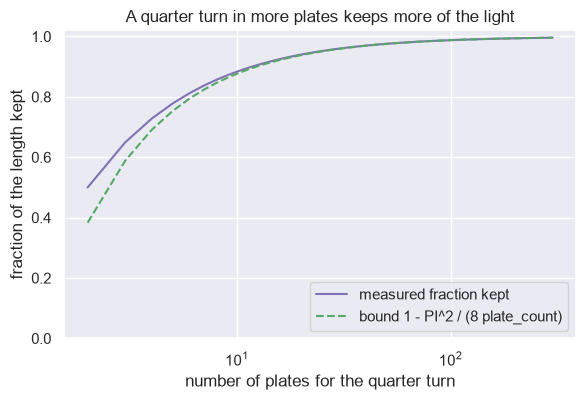

In [5]:
plate_counts = np.arange(2, 301)
kept_lengths = []
bound_holds = True
across_leftover = 0.0
formula_gap = 0.0
for plate_count in plate_counts:
    turn_angle = np.pi / (2 * plate_count)
    plate_angles = turn_angle * np.arange(1, plate_count + 1)
    outgoing = pass_through_plates(plate_angles, np.array([1.0, 0.0]))
    kept_fraction = np.cos(turn_angle) ** plate_count
    lower_bound = 1 - np.pi ** 2 / (8 * plate_count)
    kept_lengths.append(np.linalg.norm(outgoing))
    across_leftover = max(across_leftover, abs(outgoing[0]))                  # nothing left pointing across
    formula_gap = max(formula_gap, abs(outgoing[1] - kept_fraction))
    bound_holds &= lower_bound <= kept_fraction + 1e-15
kept_lengths = np.array(kept_lengths)
report("the light arrives pointing up, for plate_count 2 to 300", across_leftover < 1e-9, f"leftover across {across_leftover:.1e}")
report("the arriving length equals cos(turn_angle) ^ plate_count", formula_gap < 1e-9, f"largest gap {formula_gap:.1e}")
report("the bound 1 - PI^2 / (8 plate_count) holds for all 299 plate counts", bound_holds)
for plate_count in (2, 10, 100):
    print(f"plate_count {plate_count}: kept {np.cos(np.pi / (2 * plate_count)) ** plate_count:.4f}, bound {1 - np.pi ** 2 / (8 * plate_count):.4f}")
bound_at_100 = 1 - np.pi ** 2 / 800
report("control: the bound is not trivially loose (within 0.01 of the truth at 100 plates)",
       0 <= kept_lengths[98] - bound_at_100 < 0.01, f"gap {kept_lengths[98] - bound_at_100:.5f}")

figure, axis = plt.subplots(figsize=(6.6, 4))
axis.plot(plate_counts, kept_lengths, "-", color=MODEL, label="measured fraction kept")
axis.plot(plate_counts, 1 - np.pi ** 2 / (8 * plate_counts), "--", color=BOUND, label="bound 1 - PI^2 / (8 plate_count)")
axis.set_xscale("log")
axis.set_ylim(0.0, 1.02)
axis.set_xlabel("number of plates for the quarter turn")
axis.set_ylabel("fraction of the length kept")
axis.set_title("A quarter turn in more plates keeps more of the light")
axis.legend(loc="lower right")
save_figure(figure, "12-quarter-turn")
plt.show()

## Claim 5: merged stays merged, and dead stays dead (`merged_stays_merged`, `dead_stays_dead`)

A layer is a random function on 30 states. A stack is 12 random layers. For 300 random stacks: take every pair of states that is merged after
the first `k` layers (for `k` = 0 to 12) and check it is still merged after all the layers. For dead states, each layer is made to fix state 0,
and state 0 must be at state 0 after every prefix of the stack. Controls: pairs that were apart do sometimes merge later (so the layers really do
collapse things), and with layers that do not fix state 0 it often moves.

In [6]:
generator = np.random.default_rng(SEED + 1)
STATE_COUNT = 30
LAYER_COUNT = 12


def make_stack(fix_state_zero):
    layers = generator.integers(0, STATE_COUNT, size=(LAYER_COUNT, STATE_COUNT))
    if fix_state_zero:
        layers[:, 0] = 0
    return layers


def run_layers(layers, states):
    for layer in layers:
        states = layer[states]
    return states


all_states = np.arange(STATE_COUNT)
merged_pairs_checked = 0
broken = 0
late_merges = 0
dead_broken = 0
moved_dead = 0
for trial in range(300):
    stack = make_stack(fix_state_zero=False)
    after_all = run_layers(stack, all_states)
    merged_late = after_all[:, None] == after_all[None, :]
    for early_count in range(LAYER_COUNT + 1):
        after_early = run_layers(stack[:early_count], all_states)
        merged_early = after_early[:, None] == after_early[None, :]
        merged_pairs_checked += int(np.triu(merged_early, 1).sum())
        broken += int((merged_early & ~merged_late).sum())
        late_merges += int((~merged_early & merged_late).sum())
    dead_stack = make_stack(fix_state_zero=True)
    for prefix_count in range(LAYER_COUNT + 1):
        dead_broken += run_layers(dead_stack[:prefix_count], np.array([0]))[0] != 0
    loose_stack = make_stack(fix_state_zero=False)
    moved_dead += run_layers(loose_stack, np.array([0]))[0] != 0
report("a pair merged after the first k layers is merged at the end, 300 stacks, k = 0 to 12", broken == 0,
       f"{merged_pairs_checked} merged pairs checked, {broken} broken")
report("control: pairs that were apart do merge later", late_merges > 0, f"{late_merges} late merges")
report("a state every layer fixes stays put after every prefix", dead_broken == 0, f"{dead_broken} broken")
report("control: without the fixing, state 0 often moves", moved_dead > 50, f"{moved_dead} of 300 moved")

[PASS] a pair merged after the first k layers is merged at the end, 300 stacks, k = 0 to 12  (311390 merged pairs checked, 0 broken)
[PASS] control: pairs that were apart do merge later  (530138 late merges)
[PASS] a state every layer fixes stays put after every prefix  (0 broken)
[PASS] control: without the fixing, state 0 often moves  (293 of 300 moved)


True

## Claim 6: a chain of chains: tight features give `(1 - learning_rate * squared_length) ^ step_count` (`residual_iterate_gradientStep`)

Tight features: 8 data points, 40 weights, `matrix @ matrix.T = squared_length * identity` with `squared_length = 5` (rows from a random QR factorisation, scaled).
A gradient step on the loss `0.5 * sum(residual^2)` is `weights += learning_rate * matrix.T @ residual`. After `step_count` steps the residual must be
`(1 - learning_rate * squared_length) ^ step_count` times the starting residual, as vectors, for four learning rates. With `learning_rate = 1 / squared_length` one step must fit.
The control: with rows of different lengths (not tight) the one-factor law fails.

In [7]:
generator = np.random.default_rng(SEED + 2)
DATA_COUNT, WEIGHT_COUNT, SQUARED_LENGTH = 8, 40, 5.0
orthonormal, _ = np.linalg.qr(generator.standard_normal((WEIGHT_COUNT, DATA_COUNT)))
matrix = np.sqrt(SQUARED_LENGTH) * orthonormal.T
labels = generator.standard_normal(DATA_COUNT)
start_weights = generator.standard_normal(WEIGHT_COUNT)
report("the features are tight: matrix @ matrix.T = squared_length * identity",
       np.allclose(matrix @ matrix.T, SQUARED_LENGTH * np.eye(DATA_COUNT), atol=1e-12))


def run_gradient_steps(matrix, labels, start_weights, learning_rate, step_count):
    weights = start_weights.copy()
    residuals = [labels - matrix @ weights]
    for step in range(step_count):
        weights = weights + learning_rate * matrix.T @ residuals[-1]
        residuals.append(labels - matrix @ weights)
    return residuals


STEP_COUNT = 20
worst_gap = 0.0
for learning_rate in (0.05, 0.1, 0.19, 0.3):
    residuals = run_gradient_steps(matrix, labels, start_weights, learning_rate, STEP_COUNT)
    factor = 1 - learning_rate * SQUARED_LENGTH
    for step_count, residual in enumerate(residuals):
        worst_gap = max(worst_gap, np.abs(residual - factor ** step_count * residuals[0]).max())
report("residual after step_count steps = (1 - learning_rate * squared_length) ^ step_count * start, 4 rates, 20 steps",
       worst_gap < 1e-10, f"largest entry gap {worst_gap:.1e}")
one_step = run_gradient_steps(matrix, labels, start_weights, 1 / SQUARED_LENGTH, 1)[-1]
report("with learning_rate = 1 / squared_length one step fits", np.abs(one_step).max() < 1e-12, f"residual {np.abs(one_step).max():.1e}")
loose_matrix = matrix * generator.uniform(0.5, 1.5, size=(DATA_COUNT, 1))
loose_residuals = run_gradient_steps(loose_matrix, labels, start_weights, 0.1, 5)
loose_gap = np.abs(loose_residuals[5] - 0.5 ** 5 * loose_residuals[0]).max()
report("control: with rows of different lengths the one-factor law fails", loose_gap > 1e-3, f"gap {loose_gap:.3f}")

[PASS] the features are tight: matrix @ matrix.T = squared_length * identity
[PASS] residual after step_count steps = (1 - learning_rate * squared_length) ^ step_count * start, 4 rates, 20 steps  (largest entry gap 1.7e-15)
[PASS] with learning_rate = 1 / squared_length one step fits  (residual 8.9e-16)
[PASS] control: with rows of different lengths the one-factor law fails  (gap 0.174)


True